## 1. Import library dan pengaturan

In [2]:
import shutil
import textwrap
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from pathlib import Path
from ultralytics import YOLO

ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
DATASET = ROOT / "dataset"
RUNS = ROOT / "runs"
GRAFIK = ROOT / "hasil" / "grafik_epoch"
EVALUASI = ROOT / "hasil" / "evaluasi"

KELAS = ["logam", "paper", "plastic"]
MODEL = "yolov8n.pt"
NAMA = "wastify_yolov8n"
EPOCH = 100
PATIENCE = 20          # early stopping
BATCH = 16
UKURAN = 640

## 2. Periksa dataset dan buat `data.yaml`

In [3]:
for bagian in ("train", "val", "test"):
    if not (DATASET / "images" / bagian).exists():
        raise FileNotFoundError(f"dataset/images/{bagian} belum ada. Jalankan notebook 06 dan 07 dulu.")

data_yaml = DATASET / "data.yaml"
data_yaml.write_text(
    f"path: {DATASET.resolve().as_posix()}\n"
    "train: images/train\n"
    "val: images/val\n"
    "test: images/test\n"
    "names:\n" + "".join(f"  {i}: {k}\n" for i, k in enumerate(KELAS)),
    encoding="utf-8")

jumlah = {b: len(list((DATASET / "images" / b).glob("*.jpg"))) for b in ("train", "val", "test")}
print("Jumlah foto:", jumlah)
print(data_yaml.read_text())

Jumlah foto: {'train': 828, 'val': 79, 'test': 39}
path: D:/project semester 5/TUGAS AKHIR/WASTIFY_PCV/dataset
train: images/train
val: images/val
test: images/test
names:
  0: logam
  1: paper
  2: plastic



## 3. Latih model


In [4]:
# 1. Path file checkpoint last.pt dari training sebelumnya
last_checkpoint = RUNS / NAMA / "weights" / "last.pt"

# Cek lokasi alternatif jika YOLO menyimpan di folder 'detect'
if not last_checkpoint.exists():
    last_checkpoint = RUNS / "detect" / NAMA / "weights" / "last.pt"

# 2. Eksekusi Resume jika checkpoint ditemukan
if last_checkpoint.exists():
    print(f"[INFO] Melanjutkan pelatihan dari: {last_checkpoint}")
    model = YOLO(str(last_checkpoint))
    results = model.train(resume=True)
else:
    print(f"[INFO] Checkpoint tidak ditemukan, memulai dari awal...")
    model = YOLO(MODEL)
    results = model.train(
        data=str(data_yaml),
        epochs=EPOCH,
        patience=PATIENCE,
        imgsz=UKURAN,
        batch=BATCH,
        project=str(RUNS.resolve()),
        name=NAMA,
        seed=42
    )

# 3. Cetak lokasi file hasil akhir
folder_run = Path(model.trainer.save_dir)
best, last = folder_run / "weights" / "best.pt", folder_run / "weights" / "last.pt"
print("\nFolder hasil training:", folder_run)
print("best.pt (model terbaik) :", best, "- ada" if best.exists() else "- TIDAK ditemukan")
print("last.pt (model terakhir):", last, "- ada" if last.exists() else "- TIDAK ditemukan")

[INFO] Melanjutkan pelatihan dari: d:\project semester 5\TUGAS AKHIR\WASTIFY_PCV\runs\wastify_yolov8n\weights\last.pt
New https://pypi.org/project/ultralytics/8.4.202 available  Update with 'pip install -U ultralytics'
Ultralytics 8.4.183  Python-3.14.7 torch-2.15.0+cpu CPU (12th Gen Intel Core i5-12450H)
engine\trainer: agnostic_nms=False, amp=True, angle=1.0, augment=False, auto_augment=randaugment, batch=16, bgr=0.0, box=7.5, cache=False, cfg=None, channels_last=None, classes=None, close_mosaic=10, cls=0.5, cls_pw=0.0, cls_remap=True, compile=False, conf=None, copy_paste=0.0, copy_paste_mode=flip, cos_lr=False, cutmix=0.0, data=d:\project semester 5\TUGAS AKHIR\WASTIFY_PCV\dataset\data.yaml, degrees=0.0, deterministic=True, device=, dfl=1.5, dgrad=0.5, dis=6.0, distill_model=None, dlam=1.0, dlog=1.0, dnn=False, dropout=0.0, dynamic=False, embed=None, epochs=100, erasing=0.4, exist_ok=False, fliplr=0.5, flipud=0.0, format=torchscript, fraction=1.0, freeze=None, hsv_h=0.015, hsv_s=0.7

## 4. Evaluasi pada data testing


In [5]:
hasil_uji = YOLO(str(best)).val(data=str(data_yaml), split="test", imgsz=UKURAN,
                                project=str(RUNS.resolve()), name=NAMA + "_test", exist_ok=True)

evaluasi = pd.DataFrame({"metrik": ["Precision", "Recall", "mAP50", "mAP50-95"],
                         "nilai": [hasil_uji.box.mp, hasil_uji.box.mr, hasil_uji.box.map50, hasil_uji.box.map]}).round(4)
EVALUASI.mkdir(parents=True, exist_ok=True)
evaluasi.to_csv(EVALUASI / "evaluasi_testing.csv", index=False)
display(evaluasi)

Ultralytics 8.4.183  Python-3.14.7 torch-2.15.0+cpu CPU (12th Gen Intel Core i5-12450H)
Model summary (fused): 73 layers, 3,133,193 parameters, 0 gradients, 8.6 GFLOPs
WARNING val: Slow image access detected (ping: 0.3±0.1 ms, read: 6.8±1.3 MB/s, size: 71.1 KB). Use local storage instead of remote/mounted storage for better performance. See https://docs.ultralytics.com/guides/model-training-tips
val: Scanning D:\project semester 5\TUGAS AKHIR\WASTIFY_PCV\dataset\labels\test... 39 images, 0 backgrounds, 0 corrupt: 100% ━━━━━━━━━━━━ 39/39 231.7it/s 0.2s.4s
val: New cache created: D:\project semester 5\TUGAS AKHIR\WASTIFY_PCV\dataset\labels\test.cache
                 Class     Images  Instances      Box(P          R      mAP50  mAP50-95): 100% ━━━━━━━━━━━━ 3/3 1.2s/it 3.5s2.7s
                   all         39         39      0.901      0.864      0.923      0.614
                 logam         12         12      0.808      0.917      0.879      0.737
                 paper         15   

,metrik,nilai
0,Precision,0.9009
1,Recall,0.8637
2,mAP50,0.9232
3,mAP50-95,0.6138


## 5. Grafik perkembangan epoch



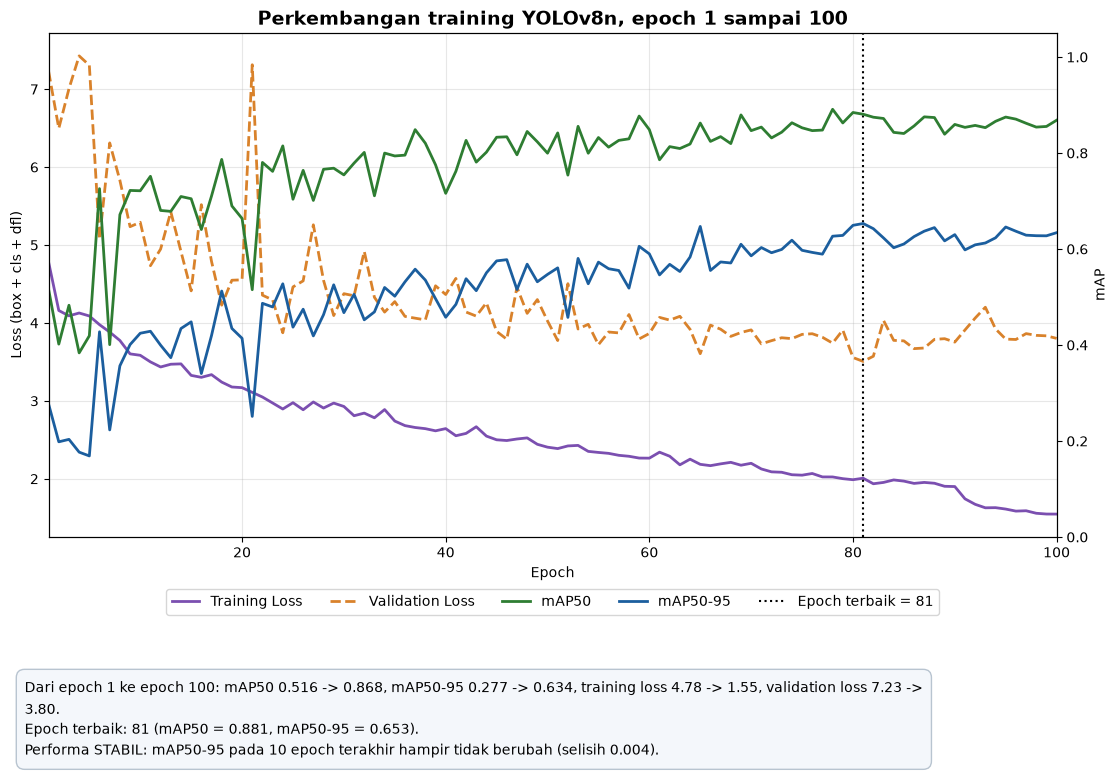

Grafik tersimpan di: d:\project semester 5\TUGAS AKHIR\WASTIFY_PCV\hasil\grafik_epoch\grafik_epoch.png
- Dari epoch 1 ke epoch 100: mAP50 0.516 -> 0.868, mAP50-95 0.277 -> 0.634, training loss 4.78 -> 1.55, validation loss 7.23 -> 3.80.
- Epoch terbaik: 81 (mAP50 = 0.881, mAP50-95 = 0.653).
- Performa STABIL: mAP50-95 pada 10 epoch terakhir hampir tidak berubah (selisih 0.004).


In [6]:
def buat_grafik(csv_path, simpan, epoch_maks):
    d = pd.read_csv(csv_path)
    d.columns = d.columns.str.strip()
    ep = d["epoch"].astype(int).to_numpy()
    if ep.min() == 0:
        ep = ep + 1                      # supaya epoch dimulai dari 1
    n = len(ep)

    loss_train = d[["train/box_loss", "train/cls_loss", "train/dfl_loss"]].sum(axis=1).to_numpy()
    loss_val = d[["val/box_loss", "val/cls_loss", "val/dfl_loss"]].sum(axis=1).to_numpy()
    map50 = d["metrics/mAP50(B)"].to_numpy()
    map5095 = d["metrics/mAP50-95(B)"].to_numpy()

    b = int(np.argmax(0.1 * map50 + 0.9 * map5095))      # indeks epoch terbaik
    iv = int(np.argmin(loss_val))                         # epoch dengan validation loss terendah

    # --- kesimpulan otomatis ---
    k = max(3, n // 10)
    if n > 10 and iv < n - 1 and loss_val[-1] > 1.1 * loss_val[iv] and loss_train[-1] < loss_train[iv]:
        status = (f"Terindikasi OVERFITTING: validation loss terendah di epoch {ep[iv]} lalu naik, sedangkan training loss "
                  f"terus turun. Karena itu dipakai bobot epoch terbaik ({ep[b]}), bukan epoch terakhir.")
    elif n > k and abs(map5095[-1] - map5095[-(k + 1)]) < 0.01:
        status = (f"Performa STABIL: mAP50-95 pada {k} epoch terakhir hampir tidak berubah "
                  f"(selisih {abs(map5095[-1] - map5095[-(k + 1)]):.3f}).")
    elif n > k and map5095[-1] > map5095[-(k + 1)]:
        status = "Performa MASIH MENINGKAT sampai epoch terakhir; menambah epoch masih berpotensi memperbaiki hasil."
    else:
        status = "Performa menurun pada akhir training; gunakan bobot epoch terbaik (best.pt)."
    awal_akhir = (f"Dari epoch {ep[0]} ke epoch {ep[-1]}: mAP50 {map50[0]:.3f} -> {map50[-1]:.3f}, "
                  f"mAP50-95 {map5095[0]:.3f} -> {map5095[-1]:.3f}, training loss {loss_train[0]:.2f} -> {loss_train[-1]:.2f}, "
                  f"validation loss {loss_val[0]:.2f} -> {loss_val[-1]:.2f}.")
    berhenti = f" Training berhenti lebih awal (early stopping) pada epoch {ep[-1]} dari {epoch_maks}." if n < epoch_maks else ""
    terbaik = (f"Epoch terbaik: {ep[b]} (mAP50 = {map50[b]:.3f}, mAP50-95 = {map5095[b]:.3f}).")
    penjelasan = [awal_akhir, terbaik + berhenti, status]

    # --- grafik tunggal dengan sumbu Y ganda ---
    fig, ax1 = plt.subplots(figsize=(12, 8))
    ax2 = ax1.twinx()
    marker = "o" if n <= 30 else None
    garis = ax1.plot(ep, loss_train, color="#7b4fb0", marker=marker, ms=4, lw=2, label="Training Loss")
    garis += ax1.plot(ep, loss_val, color="#d9822b", marker=marker, ms=4, lw=2, ls="--", label="Validation Loss")
    garis += ax2.plot(ep, map50, color="#2e7d32", marker=marker, ms=4, lw=2, label="mAP50")
    garis += ax2.plot(ep, map5095, color="#1b5e9e", marker=marker, ms=4, lw=2, label="mAP50-95")
    garis += [ax1.axvline(ep[b], color="black", ls=":", lw=1.5, label=f"Epoch terbaik = {ep[b]}")]
    ax1.set_xlabel("Epoch")
    ax1.set_ylabel("Loss (box + cls + dfl)")
    ax2.set_ylabel("mAP")
    ax2.set_ylim(0, 1.05)
    ax1.set_xlim(ep[0], ep[-1] if n > 1 else ep[0] + 1)
    ax1.grid(alpha=0.3)
    ax1.legend(garis, [g.get_label() for g in garis], loc="upper center", bbox_to_anchor=(0.5, -0.09), ncol=5, fontsize=10)
    ax1.set_title(f"Perkembangan training YOLOv8n, epoch {ep[0]} sampai {ep[-1]}", fontsize=14, fontweight="bold")

    teks = "\n".join(textwrap.fill(t, 130) for t in penjelasan)
    fig.text(0.06, 0.02, teks, fontsize=10, va="bottom", linespacing=1.5,
             bbox=dict(boxstyle="round,pad=0.6", fc="#f4f7fb", ec="#b8c4d0"))
    fig.subplots_adjust(top=0.93, bottom=0.3, left=0.08, right=0.92)
    simpan.parent.mkdir(parents=True, exist_ok=True)
    fig.savefig(simpan, dpi=200)
    plt.show()
    return penjelasan


penjelasan = buat_grafik(folder_run / "results.csv", GRAFIK / "grafik_epoch.png", EPOCH)
print("Grafik tersimpan di:", GRAFIK / "grafik_epoch.png")
for t in penjelasan:
    print("-", t)